ELECTRIC VEHICLE ADOPTION ANALYSIS

Primary Reference Data Source:
Government of India - Ministry of Road Transport and Highways (MoRTH), VAHAN Dashboard
https://vahan.parivahan.gov.in/vahan4dashboard/


**Official Data Source:** [https://vahan.parivahan.gov.in/vahan4dashboard/](https://vahan.parivahan.gov.in/vahan4dashboard/)


Note: This notebook loads the supplied Excel dataset. The VAHAN link is provided as a reference source; the dashboard is not automatically downloaded or scraped.

Upload your EV Adoption Excel file:


Saving EV_Adoption_Messy_and_Cleaned_Dataset.xlsx to EV_Adoption_Messy_and_Cleaned_Dataset.xlsx

Dataset loaded successfully!
Dataset shape: (18, 8)


,Year,State,Vehicle_Type,EV_Registrations,EV_Sales_Share_Pct,Market_Penetration_Pct,Battery_Price_USD_kWh,Data_Source
0,2020,All India,All EVs,120000.0,0.8,NaN,181.0,Vahan + industry reports
1,2021,All India,All EVs,330000.0,1.5,NaN,161.0,Vahan + industry reports
2,2022,All India,All EVs,990000.0,4.0,NaN,140.0,Vahan + industry reports
3,2023,All India,All EVs,1530000.0,6.0,NaN,132.0,Vahan + industry reports
4,2024,All India,All EVs,1950000.0,7.0,NaN,139.0,Vahan + industry reports



Column data types:
Year                               int64
State                     string[python]
Vehicle_Type              string[python]
EV_Registrations                 float64
EV_Sales_Share_Pct               float64
Market_Penetration_Pct           float64
Battery_Price_USD_kWh            float64
Data_Source               string[python]
dtype: object

Missing values in each column:
Year                       0
State                      0
Vehicle_Type               0
EV_Registrations           5
EV_Sales_Share_Pct         8
Market_Penetration_Pct    14
Battery_Price_USD_kWh     12
Data_Source                1
dtype: int64

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Year,18.0,NaN,NaN,NaN,2024.166667,1.581139,2020.0,2024.25,2025.0,2025.0,2025.0
State,18,9,All India,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vehicle_Type,18,5,All EVs,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EV_Registrations,13.0,NaN,NaN,NaN,664615.384615,771566.214318,100000.0,150000.0,250000.0,990000.0,2300000.0
EV_Sales_Share_Pct,10.0,NaN,NaN,NaN,12.7,19.032954,0.8,2.125,5.0,7.525,57.0
Market_Penetration_Pct,4.0,NaN,NaN,NaN,16.375,25.811415,2.0,2.375,4.25,18.25,55.0
Battery_Price_USD_kWh,6.0,NaN,NaN,NaN,144.666667,23.157432,115.0,133.75,139.5,155.75,181.0
Data_Source,17,2,Vahan + industry reports,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN



National trend records: 6
States with registration data: 7
Vehicle categories with sales-share data: 4


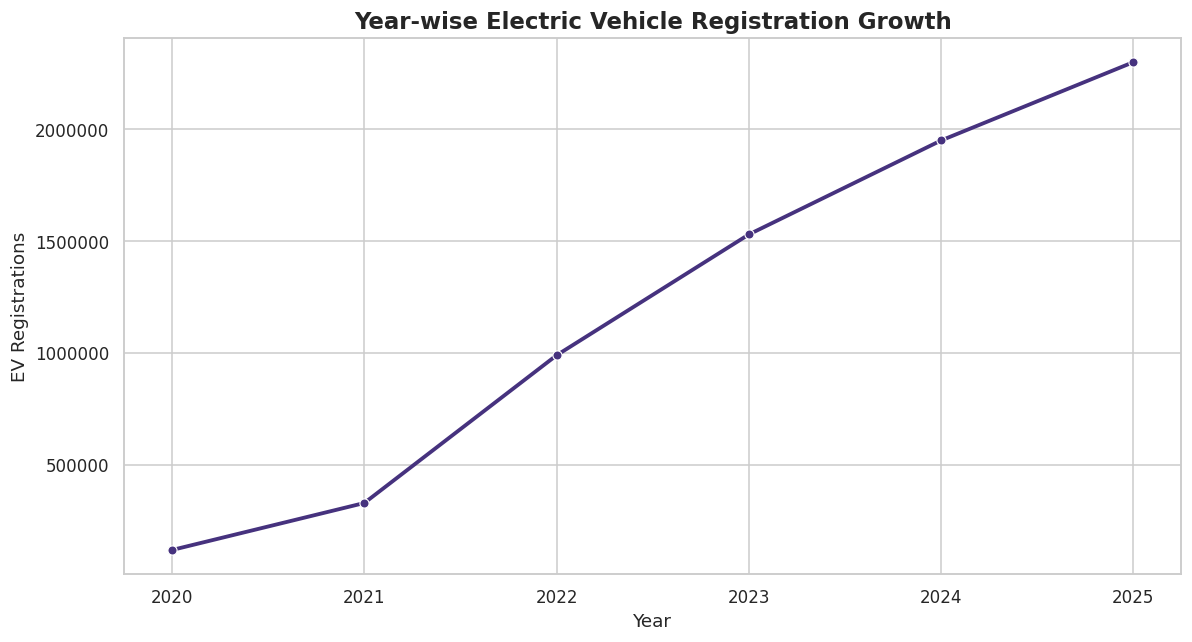

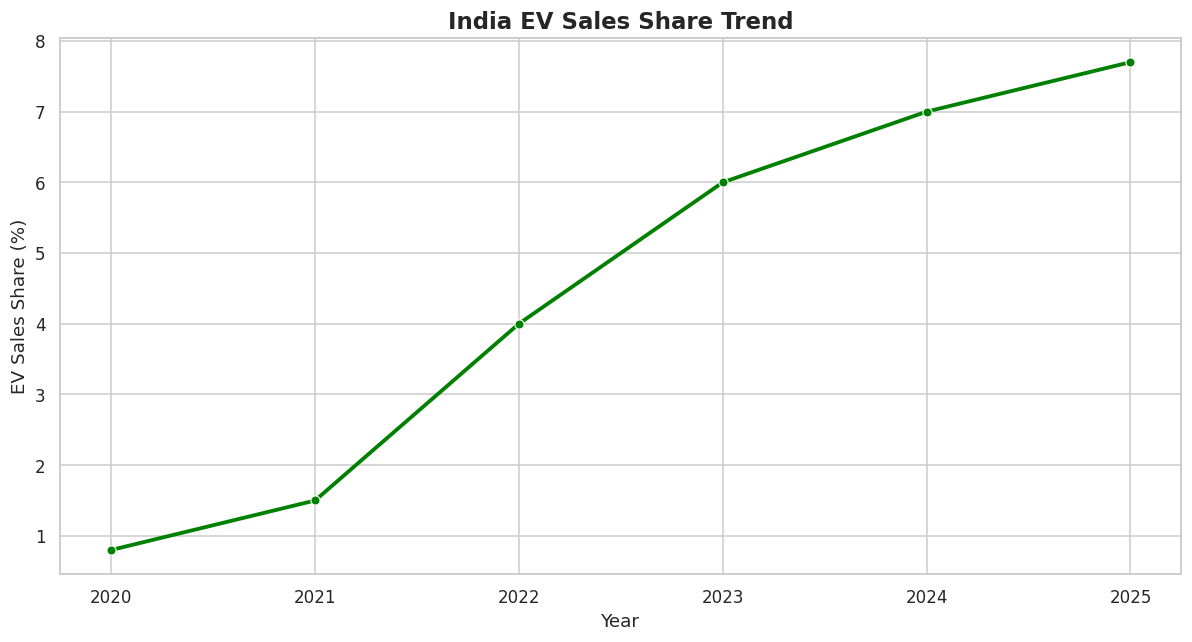

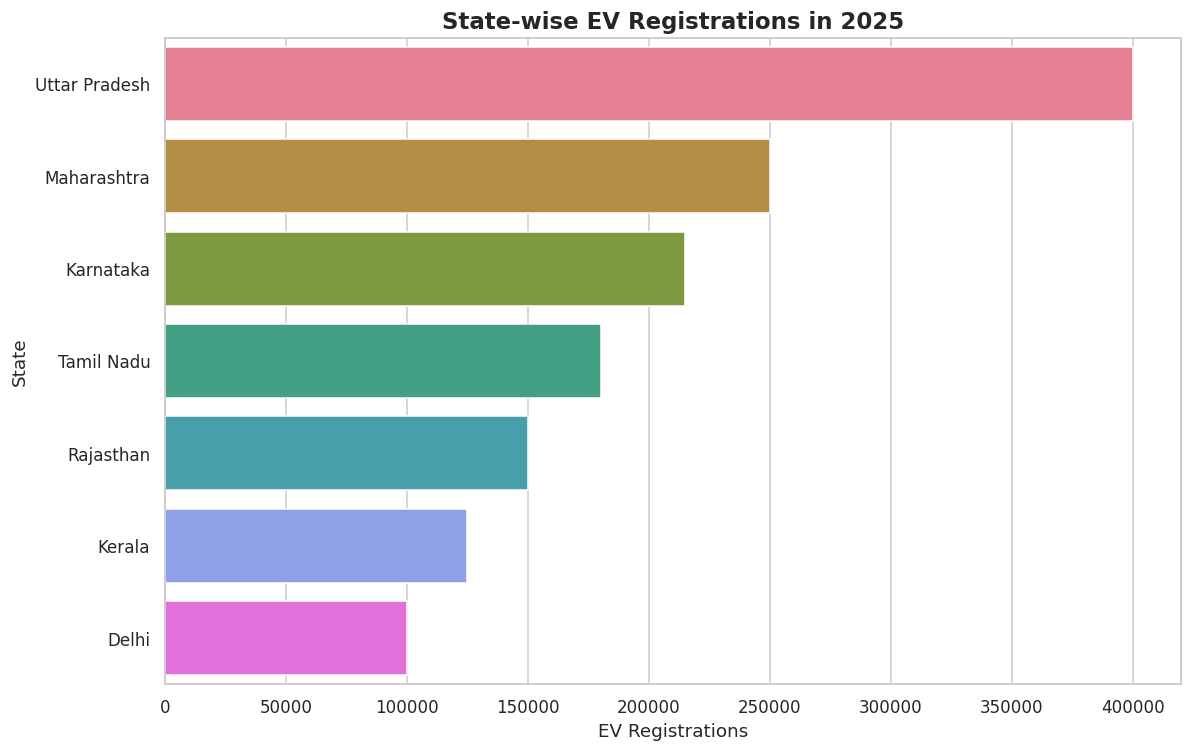

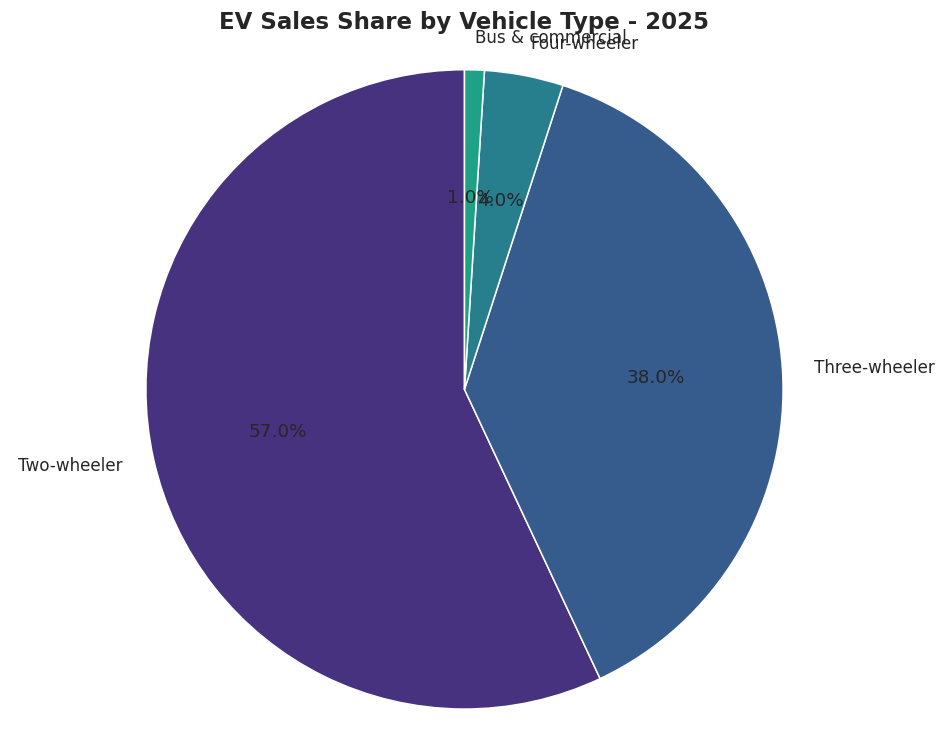

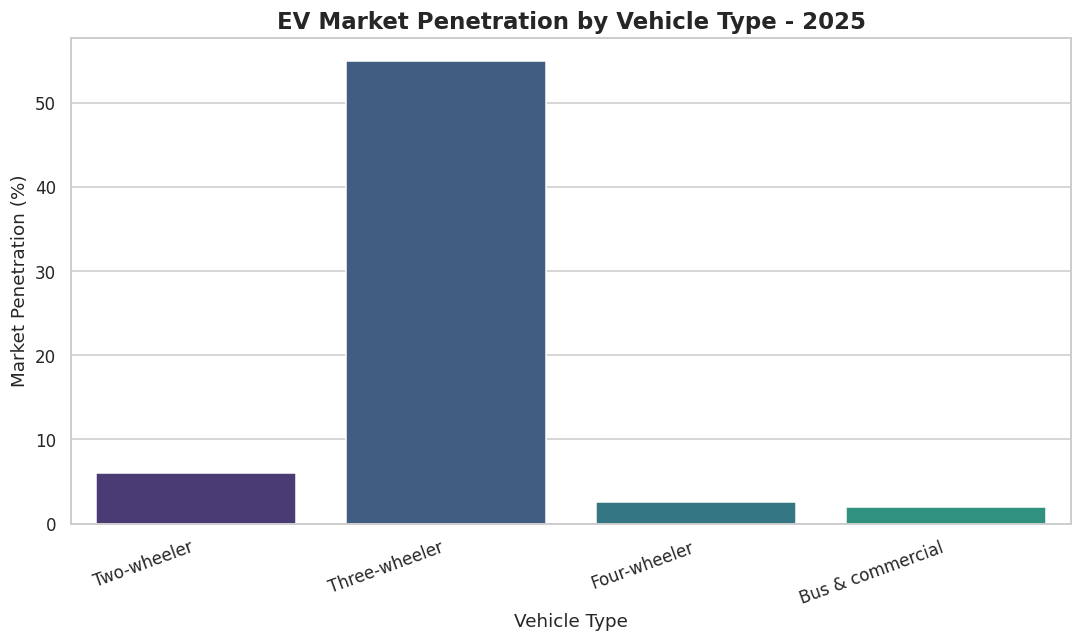

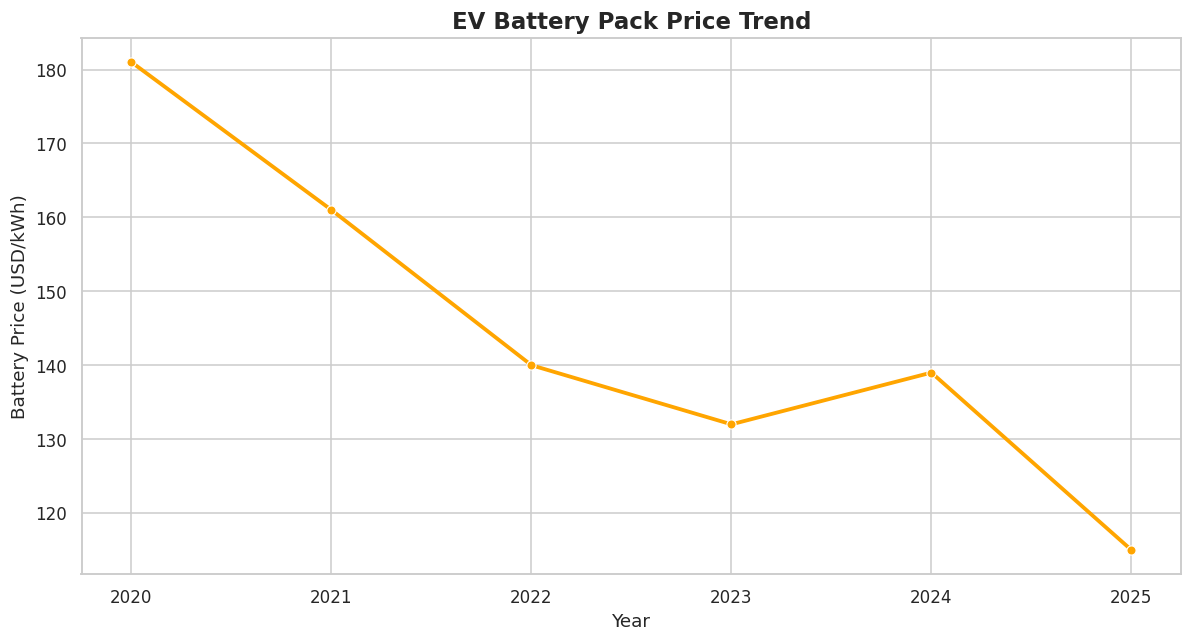

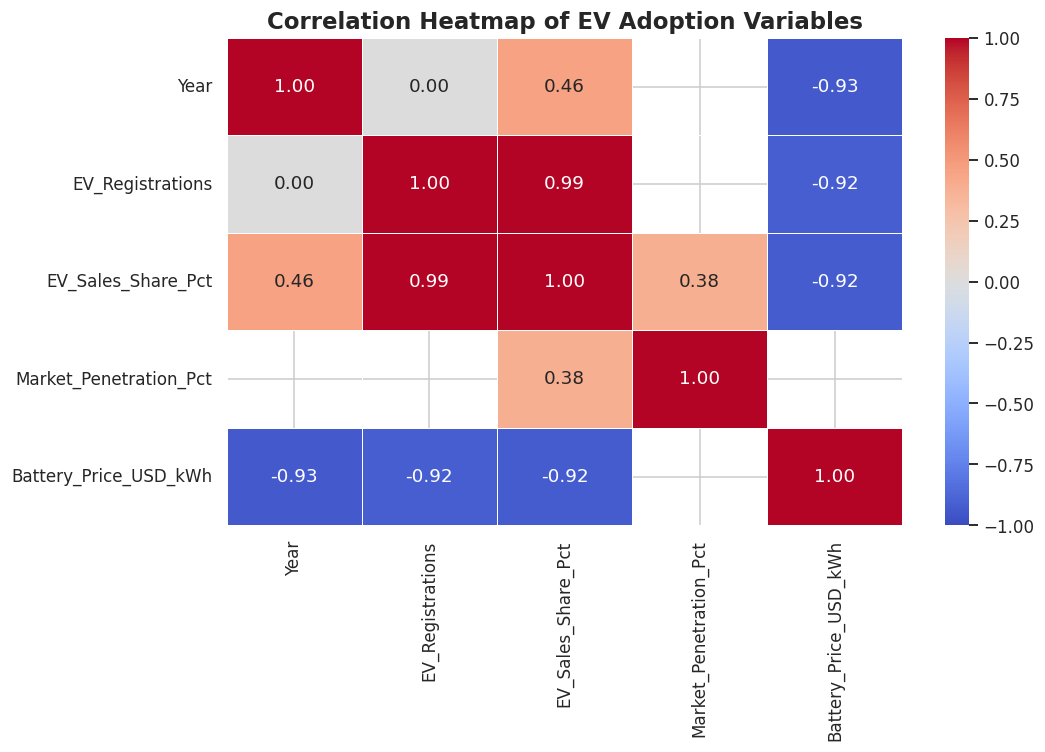

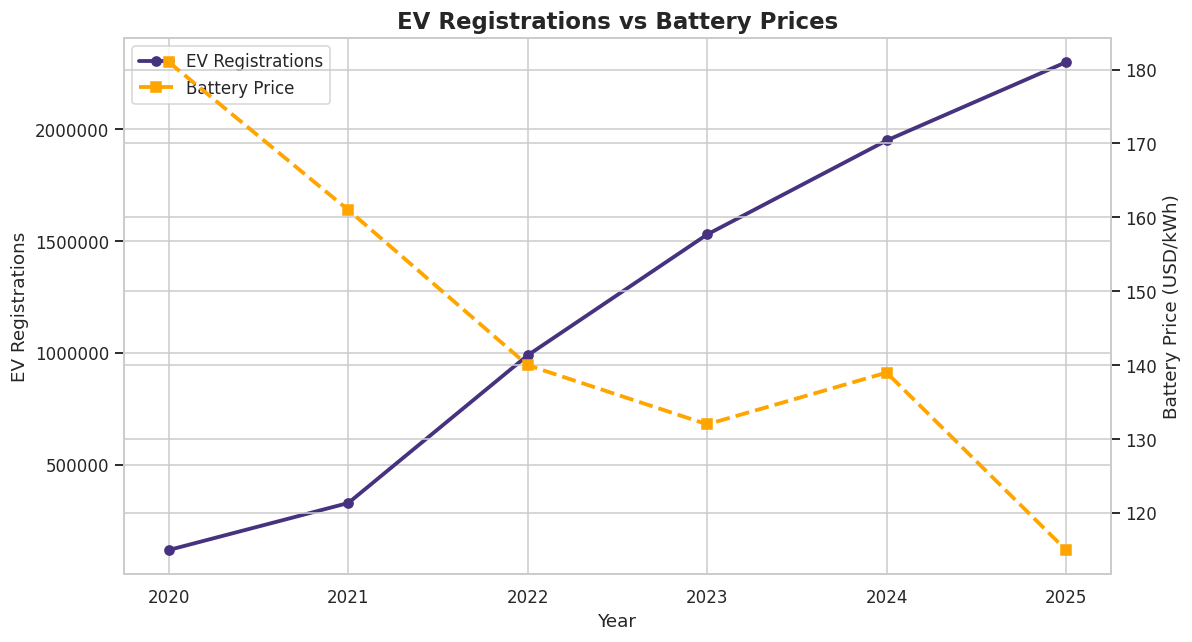

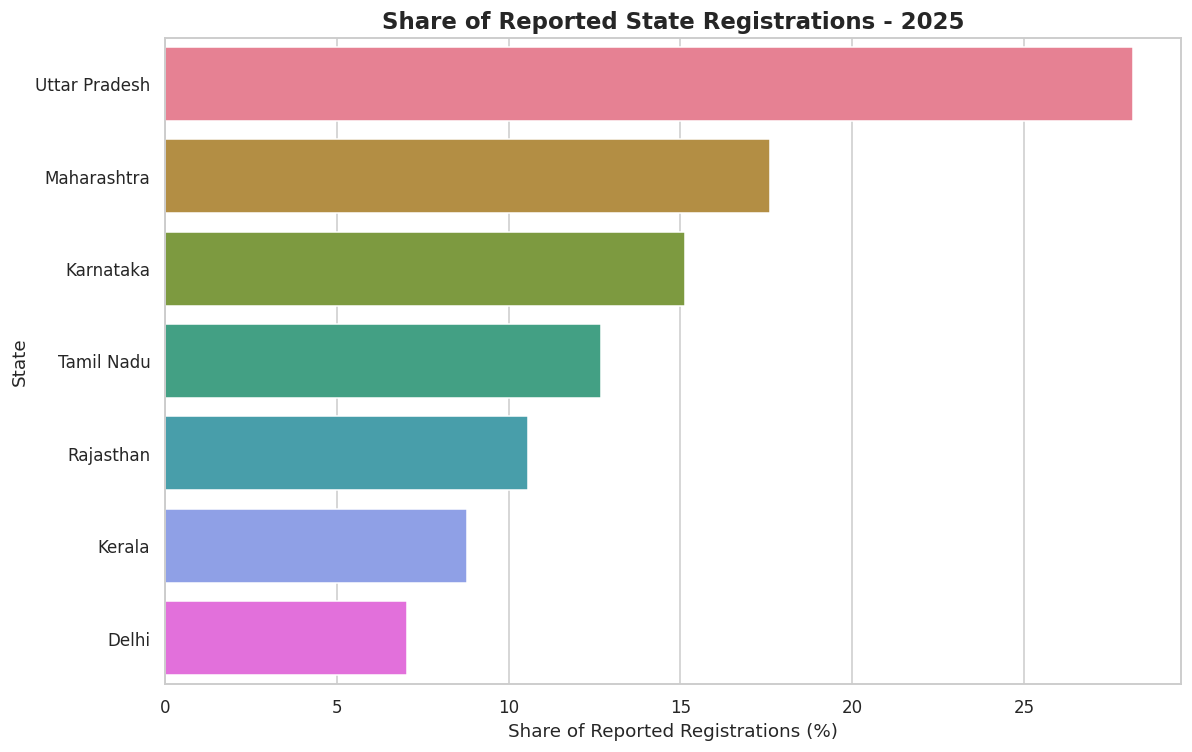


EV ADOPTION ANALYSIS - SUMMARY
First available year: 2020
Latest available year: 2025
First recorded registrations: 120,000
Latest recorded registrations: 2,300,000
Growth across available endpoints: 1816.67%

Top state in available records: Uttar Pradesh
Reported registrations: 400,000

Latest available battery price: $115.00/kWh

Analysis and visualization completed!

Official reference source:
https://vahan.parivahan.gov.in/vahan4dashboard/


**Official VAHAN Dashboard:** [Open data source](https://vahan.parivahan.gov.in/vahan4dashboard/)


Excel output created: EV_Adoption_Analysis_Output.xlsx
The Data_Source sheet contains the official reference URL.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# ELECTRIC VEHICLE (EV) ADOPTION ANALYSIS
# GOOGLE COLAB - FULL COMBINED VISUALIZATION CODE
# Dataset: EV_Adoption_Messy_and_Cleaned_Dataset.xlsx
# Sheet: Cleaned Dataset
#
# OFFICIAL DATA SOURCE:
# Government of India - VAHAN Dashboard
# https://vahan.parivahan.gov.in/vahan4dashboard/
# ============================================================


# SECTION 1: IMPORT LIBRARIES
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 110


# SECTION 2: DATA SOURCE AND PROJECT INFORMATION
# ------------------------------------------------------------

DATA_SOURCE_NAME = (
    "Government of India - Ministry of Road Transport "
    "and Highways (MoRTH), VAHAN Dashboard"
)

DATA_SOURCE_URL = (
    "https://vahan.parivahan.gov.in/vahan4dashboard/"
)

print("=" * 65)
print("ELECTRIC VEHICLE ADOPTION ANALYSIS")
print("=" * 65)

print("\nPrimary Reference Data Source:")
print(DATA_SOURCE_NAME)
print(DATA_SOURCE_URL)

display(Markdown(
    f"**Official Data Source:** [{DATA_SOURCE_URL}]"
    f"({DATA_SOURCE_URL})"
))

print(
    "\nNote: This notebook loads the supplied Excel dataset. "
    "The VAHAN link is provided as a reference source; "
    "the dashboard is not automatically downloaded or scraped."
)


# SECTION 3: UPLOAD AND LOAD THE EXCEL DATASET
# ------------------------------------------------------------

print("\nUpload your EV Adoption Excel file:")
uploaded = files.upload()

file_name = next(iter(uploaded.keys()))

# Load the cleaned dataset sheet
df = pd.read_excel(
    file_name,
    sheet_name="Cleaned Dataset"
)

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


# SECTION 4: DATA CLEANING AND VALIDATION
# ------------------------------------------------------------

# Standardize column names
df.columns = (
    df.columns.str.strip()
              .str.replace(" ", "_", regex=False)
)

# Remove duplicate records
df = df.drop_duplicates().copy()

# Standardize text columns
for col in ["State", "Vehicle_Type", "Data_Source"]:
    if col in df.columns:
        df[col] = df[col].astype("string").str.strip()

# Convert numeric columns safely
numeric_cols = [
    "Year",
    "EV_Registrations",
    "EV_Sales_Share_Pct",
    "Market_Penetration_Pct",
    "Battery_Price_USD_kWh"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )

print("\nColumn data types:")
print(df.dtypes)

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDescriptive statistics:")
display(df.describe(include="all").T)


# SECTION 5: CREATE DATA SUBSETS
# ------------------------------------------------------------

# National yearly records for overall EV trends
national = df[
    (df["State"] == "All India") &
    (df["Vehicle_Type"] == "All EVs")
].copy()

national = national.sort_values("Year")

# State-wise registrations for 2025
state_data = df[
    (df["Year"] == 2025) &
    (df["State"] != "All India") &
    (df["Vehicle_Type"] == "All EVs")
].copy()

state_data = state_data.dropna(
    subset=["EV_Registrations"]
).sort_values(
    "EV_Registrations",
    ascending=False
)

# Vehicle-type market share data
vehicle_data = df[
    (df["State"] == "All India") &
    (df["Year"] == 2025) &
    (df["Vehicle_Type"] != "All EVs")
].copy()

vehicle_data = vehicle_data.dropna(
    subset=["EV_Sales_Share_Pct"]
)

# Records with battery price observations
battery_data = national.dropna(
    subset=["Battery_Price_USD_kWh"]
).sort_values("Year")

print("\nNational trend records:", len(national))
print("States with registration data:", len(state_data))
print("Vehicle categories with sales-share data:", len(vehicle_data))


# SECTION 6: YEAR-WISE EV REGISTRATION GROWTH
# ------------------------------------------------------------

plot_data = national.dropna(
    subset=["Year", "EV_Registrations"]
).sort_values("Year")

if not plot_data.empty:
    plt.figure(figsize=(11, 6))

    sns.lineplot(
        data=plot_data,
        x="Year",
        y="EV_Registrations",
        marker="o",
        linewidth=2.5
    )

    plt.title(
        "Year-wise Electric Vehicle Registration Growth",
        fontsize=15,
        fontweight="bold"
    )
    plt.xlabel("Year")
    plt.ylabel("EV Registrations")
    plt.ticklabel_format(axis="y", style="plain")
    plt.xticks(plot_data["Year"].astype(int))
    plt.tight_layout()
    plt.show()
else:
    print("No national registration data available.")


# SECTION 7: EV SALES SHARE TREND
# ------------------------------------------------------------

plot_data = national.dropna(
    subset=["Year", "EV_Sales_Share_Pct"]
).sort_values("Year")

if not plot_data.empty:
    plt.figure(figsize=(11, 6))

    sns.lineplot(
        data=plot_data,
        x="Year",
        y="EV_Sales_Share_Pct",
        marker="o",
        linewidth=2.5,
        color="green"
    )

    plt.title(
        "India EV Sales Share Trend",
        fontsize=15,
        fontweight="bold"
    )
    plt.xlabel("Year")
    plt.ylabel("EV Sales Share (%)")
    plt.xticks(plot_data["Year"].astype(int))
    plt.tight_layout()
    plt.show()
else:
    print("No national EV sales-share observations available.")


# SECTION 8: STATE-WISE EV REGISTRATIONS IN 2025
# ------------------------------------------------------------

if not state_data.empty:
    plt.figure(figsize=(11, 7))

    sns.barplot(
        data=state_data,
        x="EV_Registrations",
        y="State",
        hue="State",
        legend=False
    )

    plt.title(
        "State-wise EV Registrations in 2025",
        fontsize=15,
        fontweight="bold"
    )
    plt.xlabel("EV Registrations")
    plt.ylabel("State")
    plt.ticklabel_format(axis="x", style="plain")
    plt.tight_layout()
    plt.show()
else:
    print("No state-wise registration values available.")


# SECTION 9: VEHICLE TYPE SALES SHARE
# ------------------------------------------------------------

if not vehicle_data.empty:
    pie_data = vehicle_data.dropna(
        subset=["Vehicle_Type", "EV_Sales_Share_Pct"]
    )

    if (
        not pie_data.empty and
        (pie_data["EV_Sales_Share_Pct"] >= 0).all() and
        pie_data["EV_Sales_Share_Pct"].sum() > 0
    ):
        plt.figure(figsize=(9, 7))

        plt.pie(
            pie_data["EV_Sales_Share_Pct"],
            labels=pie_data["Vehicle_Type"],
            autopct="%1.1f%%",
            startangle=90
        )

        plt.title(
            "EV Sales Share by Vehicle Type - 2025",
            fontsize=15,
            fontweight="bold"
        )
        plt.axis("equal")
        plt.tight_layout()
        plt.show()
    else:
        print("Vehicle-type share data cannot form a valid pie chart.")
else:
    print("No vehicle-type sales-share data available.")


# SECTION 10: MARKET PENETRATION BY VEHICLE TYPE
# ------------------------------------------------------------

if not vehicle_data.empty:
    penetration_data = vehicle_data.dropna(
        subset=["Market_Penetration_Pct"]
    )

    if not penetration_data.empty:
        plt.figure(figsize=(10, 6))

        sns.barplot(
            data=penetration_data,
            x="Vehicle_Type",
            y="Market_Penetration_Pct",
            hue="Vehicle_Type",
            legend=False
        )

        plt.title(
            "EV Market Penetration by Vehicle Type - 2025",
            fontsize=15,
            fontweight="bold"
        )
        plt.xlabel("Vehicle Type")
        plt.ylabel("Market Penetration (%)")
        plt.xticks(rotation=20, ha="right")
        plt.tight_layout()
        plt.show()
    else:
        print("No market penetration values available.")


# SECTION 11: BATTERY PRICE TREND
# ------------------------------------------------------------

if not battery_data.empty:
    plt.figure(figsize=(11, 6))

    sns.lineplot(
        data=battery_data,
        x="Year",
        y="Battery_Price_USD_kWh",
        marker="o",
        linewidth=2.5,
        color="orange"
    )

    plt.title(
        "EV Battery Pack Price Trend",
        fontsize=15,
        fontweight="bold"
    )
    plt.xlabel("Year")
    plt.ylabel("Battery Price (USD/kWh)")
    plt.xticks(battery_data["Year"].astype(int))
    plt.tight_layout()
    plt.show()
else:
    print("No battery price observations available.")


# SECTION 12: CORRELATION HEATMAP
# ------------------------------------------------------------

correlation_cols = [
    "Year",
    "EV_Registrations",
    "EV_Sales_Share_Pct",
    "Market_Penetration_Pct",
    "Battery_Price_USD_kWh"
]

correlation_cols = [
    col for col in correlation_cols
    if col in df.columns
]

corr_data = df[correlation_cols].dropna(
    axis=1,
    how="all"
)

# Remove constant columns
corr_data = corr_data.loc[
    :, corr_data.nunique(dropna=True) > 1
]

if corr_data.shape[1] >= 2:
    correlation_matrix = corr_data.corr()

    plt.figure(figsize=(10, 7))

    sns.heatmap(
        correlation_matrix,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        linewidths=0.5,
        vmin=-1,
        vmax=1
    )

    plt.title(
        "Correlation Heatmap of EV Adoption Variables",
        fontsize=15,
        fontweight="bold"
    )
    plt.tight_layout()
    plt.show()
else:
    print("Not enough variable data for a correlation heatmap.")


# SECTION 13: EV REGISTRATIONS VS BATTERY PRICES
# ------------------------------------------------------------

combined = national[
    ["Year", "EV_Registrations", "Battery_Price_USD_kWh"]
].dropna().sort_values("Year")

if not combined.empty:
    fig, ax1 = plt.subplots(figsize=(11, 6))

    ax1.plot(
        combined["Year"],
        combined["EV_Registrations"],
        marker="o",
        linewidth=2.5,
        label="EV Registrations"
    )

    ax1.set_xlabel("Year")
    ax1.set_ylabel("EV Registrations")
    ax1.ticklabel_format(axis="y", style="plain")

    ax2 = ax1.twinx()

    ax2.plot(
        combined["Year"],
        combined["Battery_Price_USD_kWh"],
        marker="s",
        linewidth=2.5,
        linestyle="--",
        color="orange",
        label="Battery Price"
    )

    ax2.set_ylabel("Battery Price (USD/kWh)")

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()

    ax1.legend(
        lines1 + lines2,
        labels1 + labels2,
        loc="best"
    )

    plt.title(
        "EV Registrations vs Battery Prices",
        fontsize=15,
        fontweight="bold"
    )
    plt.tight_layout()
    plt.show()
else:
    print("Insufficient overlapping data for combined trend chart.")


# SECTION 14: STATE REGISTRATION SHARE
# ------------------------------------------------------------

if not state_data.empty:
    total_state_registrations = state_data[
        "EV_Registrations"
    ].sum()

    if total_state_registrations > 0:
        state_share_data = state_data.copy()

        state_share_data["Registration_Share_Pct"] = (
            state_share_data["EV_Registrations"]
            / total_state_registrations
            * 100
        )

        plt.figure(figsize=(11, 7))

        sns.barplot(
            data=state_share_data,
            x="Registration_Share_Pct",
            y="State",
            hue="State",
            legend=False
        )

        plt.title(
            "Share of Reported State Registrations - 2025",
            fontsize=15,
            fontweight="bold"
        )
        plt.xlabel("Share of Reported Registrations (%)")
        plt.ylabel("State")
        plt.tight_layout()
        plt.show()


# SECTION 15: KEY SUMMARY STATISTICS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("EV ADOPTION ANALYSIS - SUMMARY")
print("=" * 65)

if not national.empty:
    national_valid = national.dropna(
        subset=["EV_Registrations"]
    ).sort_values("Year")

    if not national_valid.empty:
        first = national_valid.iloc[0]
        last = national_valid.iloc[-1]

        print(f"First available year: {int(first['Year'])}")
        print(f"Latest available year: {int(last['Year'])}")

        print(
            "First recorded registrations:",
            f"{first['EV_Registrations']:,.0f}"
        )

        print(
            "Latest recorded registrations:",
            f"{last['EV_Registrations']:,.0f}"
        )

        if first["EV_Registrations"] > 0:
            growth = (
                last["EV_Registrations"]
                / first["EV_Registrations"] - 1
            ) * 100

            print(
                f"Growth across available endpoints: {growth:.2f}%"
            )

if not state_data.empty:
    top_state = state_data.iloc[0]

    print(
        f"\nTop state in available records: {top_state['State']}"
    )

    print(
        "Reported registrations:",
        f"{top_state['EV_Registrations']:,.0f}"
    )

if not battery_data.empty:
    latest_battery = battery_data.iloc[-1]

    print(
        "\nLatest available battery price:",
        f"${latest_battery['Battery_Price_USD_kWh']:.2f}/kWh"
    )

print("\nAnalysis and visualization completed!")

print("\nOfficial reference source:")
print(DATA_SOURCE_URL)

display(Markdown(
    f"**Official VAHAN Dashboard:** "
    f"[Open data source]({DATA_SOURCE_URL})"
))


# SECTION 16: EXPORT PROCESSED DATA TO EXCEL
# ------------------------------------------------------------

output_file = "EV_Adoption_Analysis_Output.xlsx"

with pd.ExcelWriter(
    output_file,
    engine="openpyxl"
) as writer:

    df.to_excel(
        writer,
        sheet_name="Cleaned_Data",
        index=False
    )

    national.to_excel(
        writer,
        sheet_name="National_Trends",
        index=False
    )

    state_data.to_excel(
        writer,
        sheet_name="State_Analysis",
        index=False
    )

    vehicle_data.to_excel(
        writer,
        sheet_name="Vehicle_Type_Analysis",
        index=False
    )

    # Save the source information in the workbook
    source_info = pd.DataFrame({
        "Field": [
            "Project",
            "Data Source",
            "Official Source URL",
            "Dataset File",
            "Dataset Sheet"
        ],
        "Details": [
            "Electric Vehicle Adoption Analysis",
            DATA_SOURCE_NAME,
            DATA_SOURCE_URL,
            file_name,
            "Cleaned Dataset"
        ]
    })

    source_info.to_excel(
        writer,
        sheet_name="Data_Source",
        index=False
    )

print("\nExcel output created:", output_file)
print("The Data_Source sheet contains the official reference URL.")

files.download(output_file)


# ============================================================
# END OF EV ADOPTION ANALYSIS
# OFFICIAL REFERENCE:
# https://vahan.parivahan.gov.in/vahan4dashboard/
# ============================================================
